# 프로젝트 : 네이버 영화리뷰 감성분석 도전하기

이전 스텝까지는 영문 텍스트의 감정 분석을 진행해 보았습니다. 그렇다면 이번에는 한국어 텍스트의 감정 분석을 진행해 보면 어떨까요? 오늘 활용할 데이터셋은 네이버 영화의 댓글을 모아 구성된 [Naver sentiment movie corpus](https://github.com/e9t/nsmc)입니다.

아래와 같이 다운로드를 진행해 주세요.



```
$ wget https://raw.githubusercontent.com/e9t/nsmc/master/ratings_train.txt
$ wget https://raw.githubusercontent.com/e9t/nsmc/master/ratings_test.txt
$ mv ratings_*.txt ~/aiffel/sentiment_classification/data
$ pip install konlpy
$ sudo apt-get install git
$ sudo apt-get install curl
$ bash <(curl -s https://raw.githubusercontent.com/konlpy/konlpy/master/scripts/mecab.sh)

```

프로젝트 진행 순서는 다음과 같습니다.



In [ ]:
from pathlib import Path
from urllib.request import urlretrieve

DATA_DIR = Path('/content') if Path('/content').exists() else Path.cwd()
for filename in ('ratings_train.txt', 'ratings_test.txt'):
    target = DATA_DIR / filename
    if not target.exists():
        urlretrieve(f'https://raw.githubusercontent.com/e9t/nsmc/master/{filename}', target)
print('Data directory:', DATA_DIR)
%pip install konlpy gensim


In [2]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 39.7 MB/s  0:00:00


## 라이브러리 버전을 확인해 봅니다
---
사용할 라이브러리 버전을 둘러봅시다.

In [3]:
import pandas
import konlpy
import gensim

print(pandas.__version__)
print(konlpy.__version__)
print(gensim.__version__)

2.2.3
0.6.0
4.4.0


## 1) 데이터 준비와 확인
---

In [ ]:
import pandas as pd

train_data = pd.read_table(DATA_DIR / 'ratings_train.txt')
test_data = pd.read_table(DATA_DIR / 'ratings_test.txt')
train_data.head()


## 2) 데이터로더 구성
---
실습 때 다루었던 IMDB 데이터셋은 텍스트를 가공하여 `imdb.data_loader()` 메서드를 호출하면 숫자 인덱스로 변환된 텍스트와 `word_to_index` 딕셔너리까지 친절하게 제공합니다. 그러나 이번에 다루게 될 nsmc 데이터셋은 전혀 가공되지 않은 텍스트 파일로 이루어져 있습니다. 이것을 읽어서 `imdb.data_loader()`와 동일하게 동작하는 자신만의 `data_loader`를 만들어 보는 것으로 시작합니다. `data_loader` 안에서는 다음을 수행해야 합니다.

- 데이터의 중복 제거
- NaN 결측치 제거
- 한국어 토크나이저로 토큰화
- 불용어(Stopwords) 제거
- 사전`word_to_index` 구성
- 텍스트 스트링을 사전 인덱스 스트링으로 변환
- `X_train`, `y_train`, `X_test`, `y_test`, `word_to_index` 리턴

### MeCab 설치 오류와 해결

기존 Python 3.13 Linux 실행에서 python-mecab-ko 빌드가 실패했다.
python-mecab-ko-py313 설치 후 형태소 분석이 성공했다. 아래 셀은 Python 버전에 따라
패키지를 선택한다. 다른 운영체제에서는 환경에 맞는 MeCab 설치가 필요할 수 있다.

In [ ]:
import subprocess
import sys

mecab_package = (
    'python-mecab-ko-py313'
    if sys.version_info[:2] == (3, 13)
    else 'python-mecab-ko'
)
subprocess.check_call([sys.executable, '-m', 'pip', 'install', mecab_package])

In [14]:
from mecab import MeCab

tokenizer = MeCab()

print(tokenizer.morphs("이 영화는 정말 재미있어요"))

['이', '영화', '는', '정말', '재미있', '어요']


In [15]:
from mecab import MeCab
import numpy as np
from collections import Counter

tokenizer = MeCab()
stopwords = ['의','가','이','은','들','는','좀','잘','걍','과','도','를','으로','자','에','와','한','하다']

def load_data(train_data, test_data, num_words=10000):
    train_data.drop_duplicates(subset=['document'], inplace=True)
    train_data = train_data.dropna(how = 'any')
    test_data.drop_duplicates(subset=['document'], inplace=True)
    test_data = test_data.dropna(how = 'any')

    X_train = []
    for sentence in train_data['document']:
        temp_X = tokenizer.morphs(sentence) # 토큰화
        temp_X = [word for word in temp_X if not word in stopwords] # 불용어 제거
        X_train.append(temp_X)

    X_test = []
    for sentence in test_data['document']:
        temp_X = tokenizer.morphs(sentence) # 토큰화
        temp_X = [word for word in temp_X if not word in stopwords] # 불용어 제거
        X_test.append(temp_X)

    words = np.concatenate(X_train).tolist()
    counter = Counter(words)
    counter = counter.most_common(10000-4)
    vocab = ['', '', '', ''] + [key for key, _ in counter]
    word_to_index = {word:index for index, word in enumerate(vocab)}

    def wordlist_to_indexlist(wordlist):
        return [word_to_index[word] if word in word_to_index else word_to_index[''] for word in wordlist]

    X_train = list(map(wordlist_to_indexlist, X_train))
    X_test = list(map(wordlist_to_indexlist, X_test))

    return X_train, np.array(list(train_data['label'])), X_test, np.array(list(test_data['label'])), word_to_index

X_train, y_train, X_test, y_test, word_to_index = load_data(train_data, test_data)

In [16]:
index_to_word = {index:word for word, index in word_to_index.items()}

In [17]:
# 문장 1개를 활용할 딕셔너리와 함께 주면, 단어 인덱스 리스트 벡터로 변환해 주는 함수입니다.
# 단, 모든 문장은 <BOS>로 시작하는 것으로 합니다.
def get_encoded_sentence(sentence, word_to_index):
    return [word_to_index['<BOS>']]+[word_to_index[word] if word in word_to_index else word_to_index['<UNK>'] for word in sentence.split()]

# 여러 개의 문장 리스트를 한꺼번에 단어 인덱스 리스트 벡터로 encode해 주는 함수입니다.
def get_encoded_sentences(sentences, word_to_index):
    return [get_encoded_sentence(sentence, word_to_index) for sentence in sentences]

# 숫자 벡터로 encode된 문장을 원래대로 decode하는 함수입니다.
def get_decoded_sentence(encoded_sentence, index_to_word):
    return ' '.join(index_to_word[index] if index in index_to_word else '<UNK>' for index in encoded_sentence[1:])  #[1:]를 통해 <BOS>를 제외

# 여러 개의 숫자 벡터로 encode된 문장을 한꺼번에 원래대로 decode하는 함수입니다.
def get_decoded_sentences(encoded_sentences, index_to_word):
    return [get_decoded_sentence(encoded_sentence, index_to_word) for encoded_sentence in encoded_sentences]

In [18]:

# Fix special-token names while keeping existing indices

word_to_index = {
    word: index
    for word, index in word_to_index.items()
    if word != ''
}

word_to_index.update({
    '<PAD>': 0,
    '<BOS>': 1,
    '<UNUSED>': 2,
    '<UNK>': 3
})

index_to_word = {
    index: word
    for word, index in word_to_index.items()
}

print("Vocabulary size:", len(word_to_index))
print("Special tokens:", {
    token: word_to_index[token]
    for token in ['<PAD>', '<BOS>', '<UNUSED>', '<UNK>']
})


Vocabulary size: 10000
Special tokens: {'<PAD>': 0, '<BOS>': 1, '<UNUSED>': 2, '<UNK>': 3}


## 3) 모델 구성을 위한 데이터 분석 및 가공
---
- 데이터셋 내 문장 길이 분포
- 적절한 최대 문장 길이 지정
- keras.preprocessing.sequence.pad_sequences 을 활용한 패딩 추가

Number of reviews: 146182
Average length: 15.981673530256803
Median length: 12.0
Maximum length: 116
95th percentile: 47.0


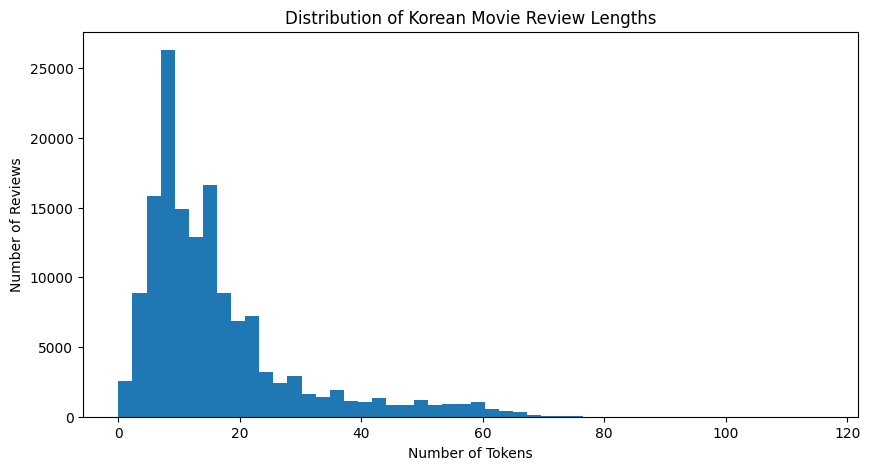

In [19]:

import numpy as np
import matplotlib.pyplot as plt

# Count the number of tokens in each review
train_lengths = np.array([len(review) for review in X_train])

print("Number of reviews:", len(X_train))
print("Average length:", np.mean(train_lengths))
print("Median length:", np.median(train_lengths))
print("Maximum length:", np.max(train_lengths))
print("95th percentile:", np.percentile(train_lengths, 95))

plt.figure(figsize=(10, 5))
plt.hist(train_lengths, bins=50)
plt.title("Distribution of Korean Movie Review Lengths")
plt.xlabel("Number of Tokens")
plt.ylabel("Number of Reviews")
plt.show()


In [20]:

maxlen = max(1, int(np.ceil(np.percentile(train_lengths, 95))))

print("Selected maximum length:", maxlen)

coverage = np.mean(train_lengths <= maxlen) * 100
print(f"Reviews covered without truncation: {coverage:.2f}%")


Selected maximum length: 47
Reviews covered without truncation: 95.23%


In [21]:

from tensorflow.keras.preprocessing.sequence import pad_sequences

X_train_pad = pad_sequences(
    X_train,
    value=word_to_index['<PAD>'],
    padding='post',
    truncating='post',
    maxlen=maxlen
)

X_test_pad = pad_sequences(
    X_test,
    value=word_to_index['<PAD>'],
    padding='post',
    truncating='post',
    maxlen=maxlen
)

print("Training shape:", X_train_pad.shape)
print("Testing shape:", X_test_pad.shape)

print("Original:", X_train[0])
print("Padded:", X_train_pad[0])


Training shape: (146182, 47)
Testing shape: (49157, 47)
Original: [32, 74, 919, 4, 4, 39, 228, 20, 33, 748]
Padded: [ 32  74 919   4   4  39 228  20  33 748   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0]


## 4) 모델 구성 및 validation set 구성
---
모델은 3가지 이상 다양하게 구성하여 실험해 보세요.

In [22]:

from sklearn.model_selection import train_test_split

X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train_pad,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training data:", X_train_final.shape)
print("Validation data:", X_val.shape)
print("Test data:", X_test_pad.shape)


Training data: (116945, 47)
Validation data: (29237, 47)
Test data: (49157, 47)


In [23]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

vocab_size = max(word_to_index.values()) + 1
embedding_dim = 100
epochs = 5
batch_size = 128

print("Vocabulary size:", vocab_size)
print("Embedding dimension:", embedding_dim)
print("Maximum sequence length:", maxlen)


Vocabulary size: 10000
Embedding dimension: 100
Maximum sequence length: 47


In [24]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# A custom pooling layer that safely ignores padding
class SafeAveragePooling(layers.Layer):
    def call(self, inputs):
        embeddings, token_ids = inputs

        # 1 for real tokens, 0 for padding
        mask = tf.cast(
            tf.not_equal(token_ids, 0),
            embeddings.dtype
        )

        mask = tf.expand_dims(mask, axis=-1)

        # Sum embeddings of real tokens
        summed = tf.reduce_sum(
            embeddings * mask,
            axis=1
        )

        # Count real tokens (minimum 1 avoids division by zero)
        counts = tf.maximum(
            tf.reduce_sum(mask, axis=1),
            1.0
        )

        return summed / counts


# Build the corrected model
inputs = keras.Input(shape=(maxlen,), dtype='int32')

embeddings = layers.Embedding(
    input_dim=vocab_size,
    output_dim=embedding_dim
)(inputs)

pooled = SafeAveragePooling()([embeddings, inputs])

x = layers.Dense(32, activation='relu')(pooled)
outputs = layers.Dense(1, activation='sigmoid')(x)

model_avg = keras.Model(
    inputs=inputs,
    outputs=outputs,
    name="SafeGlobalAveragePooling"
)

model_avg.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model_avg.summary()


Model: "SafeGlobalAveragePooling"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 47)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 47, 100)   │  1,000,000 │ input_layer[0][0] │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ safe_average_pooli… │ (None, 100)       │          0 │ embedding[0][0],  │
│ (SafeAveragePoolin… │                   │            │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 32)        │      3,232 │ safe_average_poo… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │         33 │ dense[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,003,265 (3.83 MB)

 Trainable params: 1,003,265 (3.83 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:

model_lstm = keras.Sequential([
    layers.Input(shape=(maxlen,)),
    layers.Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        mask_zero=True
    ),
    layers.LSTM(64),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
], name="LSTM")

model_lstm.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model_lstm.summary()


Model: "LSTM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 47, 100)        │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        42,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,046,465 (3.99 MB)

 Trainable params: 1,046,465 (3.99 MB)

 Non-trainable params: 0 (0.00 B)

## 5) 모델 훈련 개시
---

In [26]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

# Reproducibility
tf.keras.utils.set_random_seed(42)

# Training settings
vocab_size = max(word_to_index.values()) + 1
embedding_dim = 100
batch_size = 128
epochs = 10

# Check the datasets
print("Training shape:", X_train_final.shape)
print("Validation shape:", X_val.shape)
print("Testing shape:", X_test_pad.shape)

print("\nVocabulary size:", vocab_size)
print("Embedding dimension:", embedding_dim)
print("Maximum length:", maxlen)

# Check for invalid values
assert np.isfinite(X_train_final).all()
assert np.isfinite(X_val).all()
assert np.isfinite(y_train_final).all()
assert np.isfinite(y_val).all()

# Check for empty reviews
empty_train = np.sum(
    np.all(X_train_final == 0, axis=1)
)
empty_val = np.sum(
    np.all(X_val == 0, axis=1)
)

print("\nEmpty training reviews:", empty_train)
print("Empty validation reviews:", empty_val)


Training shape: (116945, 47)
Validation shape: (29237, 47)
Testing shape: (49157, 47)

Vocabulary size: 10000
Embedding dimension: 100
Maximum length: 47

Empty training reviews: 2
Empty validation reviews: 1


In [27]:

class SafeAveragePooling(layers.Layer):
    def call(self, inputs):
        embeddings, token_ids = inputs

        # Create mask: 1 = real word, 0 = padding
        mask = tf.cast(
            tf.not_equal(token_ids, 0),
            embeddings.dtype
        )
        mask = tf.expand_dims(mask, axis=-1)

        # Sum embeddings of valid words
        summed = tf.reduce_sum(
            embeddings * mask,
            axis=1
        )

        # Avoid dividing by zero
        counts = tf.maximum(
            tf.reduce_sum(mask, axis=1),
            1.0
        )

        return summed / counts


def build_avg_model():
    inputs = keras.Input(
        shape=(maxlen,),
        dtype="int32"
    )

    x = layers.Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        name="avg_embedding"
    )(inputs)

    x = SafeAveragePooling()([x, inputs])
    x = layers.Dense(32, activation="relu")(x)

    outputs = layers.Dense(
        1,
        activation="sigmoid"
    )(x)

    model = keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="GlobalAveragePooling"
    )

    return model


In [28]:

def build_cnn_model():
    model = keras.Sequential([
        layers.Input(shape=(maxlen,)),

        layers.Embedding(
            input_dim=vocab_size,
            output_dim=embedding_dim,
            name="cnn_embedding"
        ),

        layers.Conv1D(
            filters=128,
            kernel_size=5,
            activation="relu"
        ),

        layers.GlobalMaxPooling1D(),

        layers.Dense(64, activation="relu"),
        layers.Dropout(0.5),

        layers.Dense(1, activation="sigmoid")
    ], name="CNN")

    return model


def build_lstm_model():
    model = keras.Sequential([
        layers.Input(shape=(maxlen,)),

        layers.Embedding(
            input_dim=vocab_size,
            output_dim=embedding_dim,
            mask_zero=True,
            name="lstm_embedding"
        ),

        layers.LSTM(64),

        layers.Dense(64, activation="relu"),
        layers.Dropout(0.5),

        layers.Dense(1, activation="sigmoid")
    ], name="LSTM")

    return model


In [29]:

models = {
    "GlobalAveragePooling": build_avg_model(),
    "CNN": build_cnn_model(),
    "LSTM": build_lstm_model()
}

for name, model in models.items():

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=0.001
        ),
        loss="binary_crossentropy",
        metrics=["accuracy"]
    )

    print(f"\n{'='*50}")
    print(f"Model: {name}")
    print(f"{'='*50}")

    model.summary()



Model: GlobalAveragePooling


Model: "GlobalAveragePooling"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 47)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ avg_embedding       │ (None, 47, 100)   │  1,000,000 │ input_layer_2[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ safe_average_pooli… │ (None, 100)       │          0 │ avg_embedding[0]… │
│ (SafeAveragePoolin… │                   │            │ input_layer_2[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 32)        │      3,232 │ safe_average_poo… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 1)         │         33 │ dense_4[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,003,265 (3.83 MB)

 Trainable params: 1,003,265 (3.83 MB)

 Non-trainable params: 0 (0.00 B)

... (8 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_embedding (Embedding)      │ (None, 47, 100)        │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        42,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,046,465 (3.99 MB)

 Trainable params: 1,046,465 (3.99 MB)

 Non-trainable params: 0 (0.00 B)

In [30]:

histories = {}

for name, model in models.items():

    print(f"\n{'='*60}")
    print(f"Training: {name}")
    print(f"{'='*60}")

    early_stopping = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        mode="min"
    )

    terminate_nan = keras.callbacks.TerminateOnNaN()

    history = model.fit(
        X_train_final,
        y_train_final,
        epochs=epochs,
        batch_size=batch_size,
        validation_data=(X_val, y_val),
        callbacks=[
            early_stopping,
            terminate_nan
        ],
        verbose=1
    )

    histories[name] = history

    print(f"\n{name} training finished!")
    print("Epochs completed:", len(history.history["loss"]))
    print(
        "Best validation loss:",
        min(history.history["val_loss"])
    )



Training: GlobalAveragePooling
Epoch 1/10
914/914 ━━━━━━━━━━━━━━━━━━━━ 29s 29ms/step - accuracy: 0.8234 - loss: 0.4052 - val_accuracy: 0.8466 - val_loss: 0.3592
Epoch 2/10
914/914 ━━━━━━━━━━━━━━━━━━━━ 16s 18ms/step - accuracy: 0.8577 - loss: 0.3338 - val_accuracy: 0.8460 - val_loss: 0.3588
Epoch 3/10
914/914 ━━━━━━━━━━━━━━━━━━━━ 16s 18ms/step - accuracy: 0.8655 - loss: 0.3125 - val_accuracy: 0.8429 - val_loss: 0.3665
Epoch 4/10
914/914 ━━━━━━━━━━━━━━━━━━━━ 21s 23ms/step - accuracy: 0.8720 - loss: 0.2972 - val_accuracy: 0.8413 - val_loss: 0.3778

GlobalAveragePooling training finished!
Epochs completed: 4
Best validation loss: 0.35884180665016174

Training: CNN
Epoch 1/10
914/914 ━━━━━━━━━━━━━━━━━━━━ 69s 74ms/step - accuracy: 0.8252 - loss: 0.3886 - val_accuracy: 0.8582 - val_loss: 0.3255
Epoch 2/10
914/914 ━━━━━━━━━━━━━━━━━━━━ 67s 73ms/step - accuracy: 0.8891 - loss: 0.2732 - val_accuracy: 0.8583 - val_loss: 0.3424
Epoch 3/10
914/914 ━━━━━━━━━━━━━━━━━━━━ 66s 72ms/step - accuracy: 0.92

In [31]:

results = []

for name, model in models.items():

    val_loss, val_accuracy = model.evaluate(
        X_val,
        y_val,
        verbose=0
    )

    history = histories[name].history

    results.append({
        "Model": name,
        "Epochs Trained": len(history["loss"]),
        "Best Epoch (Val Loss)": (
            int(np.argmin(history["val_loss"])) + 1
        ),
        "Validation Loss": val_loss,
        "Validation Accuracy": val_accuracy
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Validation Accuracy",
    ascending=False
).reset_index(drop=True)

display(results_df)

# Select best model based on validation accuracy
best_model_name = results_df.loc[0, "Model"]
best_model = models[best_model_name]

print("\nBest model:", best_model_name)


,Model,Epochs Trained,Best Epoch (Val Loss),Validation Loss,Validation Accuracy
0,LSTM,4,2,0.333235,0.860075
1,CNN,3,1,0.325472,0.858159
2,GlobalAveragePooling,4,2,0.358842,0.846017



Best model: LSTM


In [32]:

test_loss, test_accuracy = best_model.evaluate(
    X_test_pad,
    y_test,
    verbose=0
)

print("Best model:", best_model_name)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test accuracy (%): {test_accuracy * 100:.2f}%")


Best model: LSTM
Test loss: 0.3393
Test accuracy: 0.8549
Test accuracy (%): 85.49%


## 6) Loss, Accuracy 그래프 시각화
---

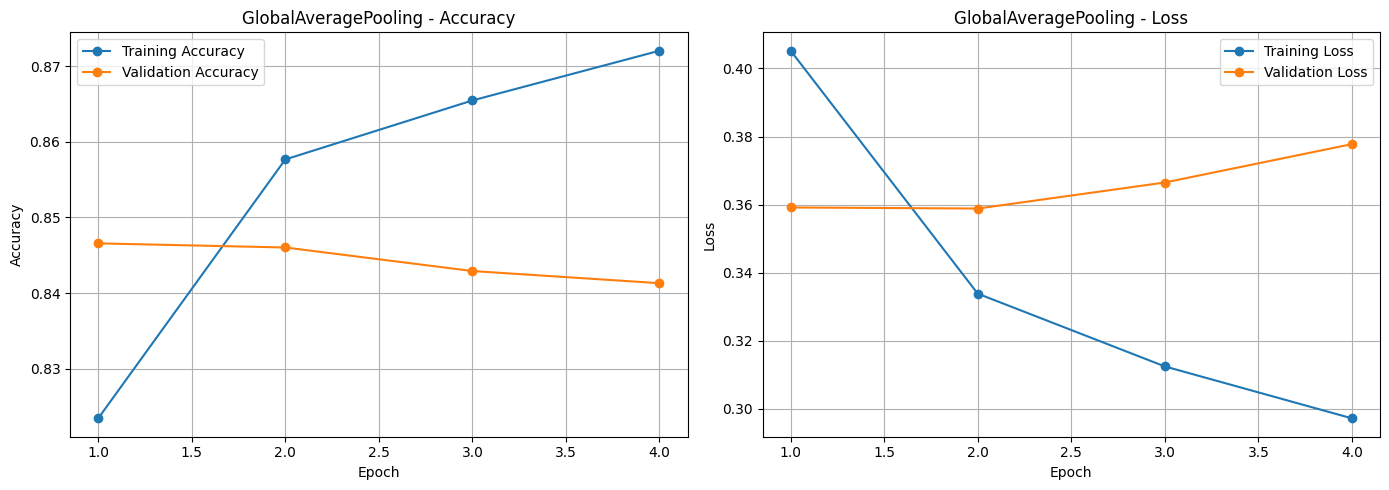

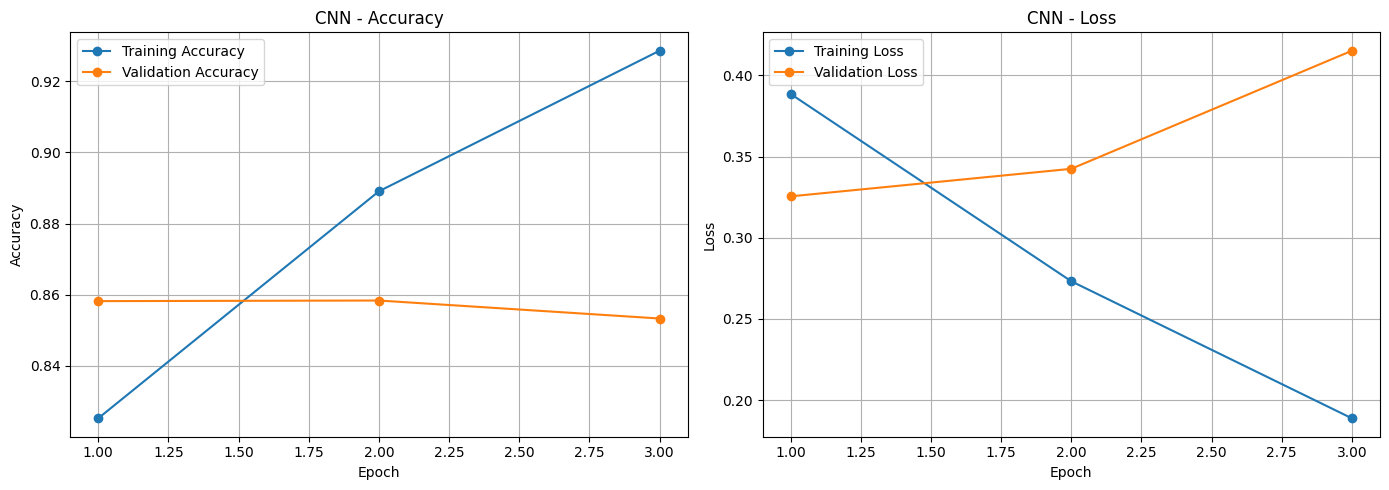

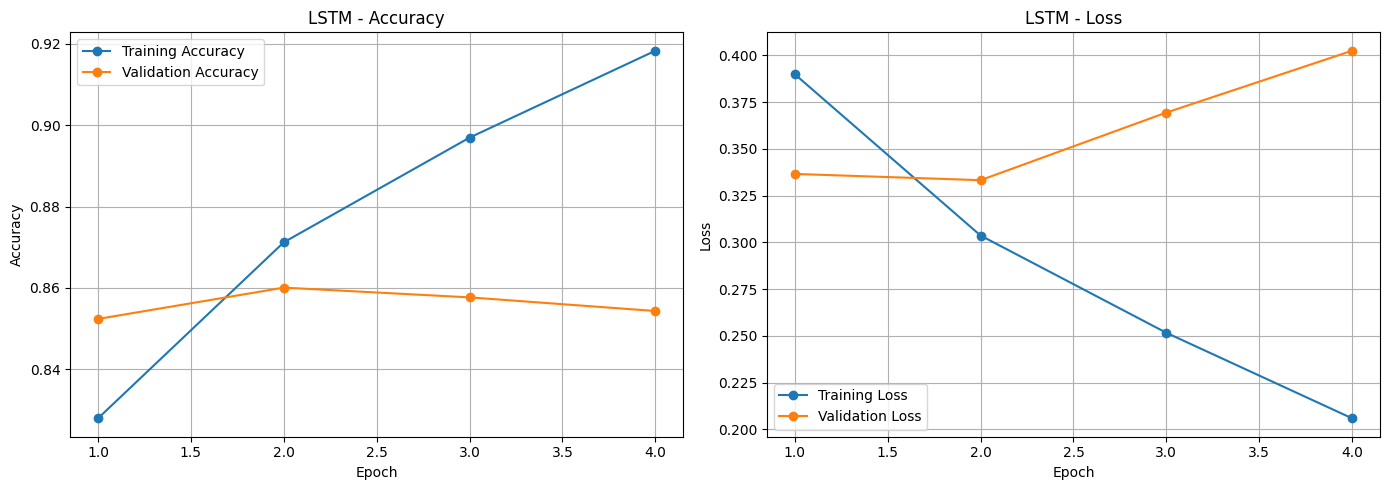

In [33]:

for name, history in histories.items():

    train_acc = history.history["accuracy"]
    val_acc = history.history["val_accuracy"]

    train_loss = history.history["loss"]
    val_loss = history.history["val_loss"]

    epoch_range = range(1, len(train_acc) + 1)

    plt.figure(figsize=(14, 5))

    # Accuracy graph
    plt.subplot(1, 2, 1)

    plt.plot(
        epoch_range,
        train_acc,
        marker="o",
        label="Training Accuracy"
    )

    plt.plot(
        epoch_range,
        val_acc,
        marker="o",
        label="Validation Accuracy"
    )

    plt.title(f"{name} - Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid(True)

    # Loss graph
    plt.subplot(1, 2, 2)

    plt.plot(
        epoch_range,
        train_loss,
        marker="o",
        label="Training Loss"
    )

    plt.plot(
        epoch_range,
        val_loss,
        marker="o",
        label="Validation Loss"
    )

    plt.title(f"{name} - Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid(True)

    plt.tight_layout()
    plt.show()


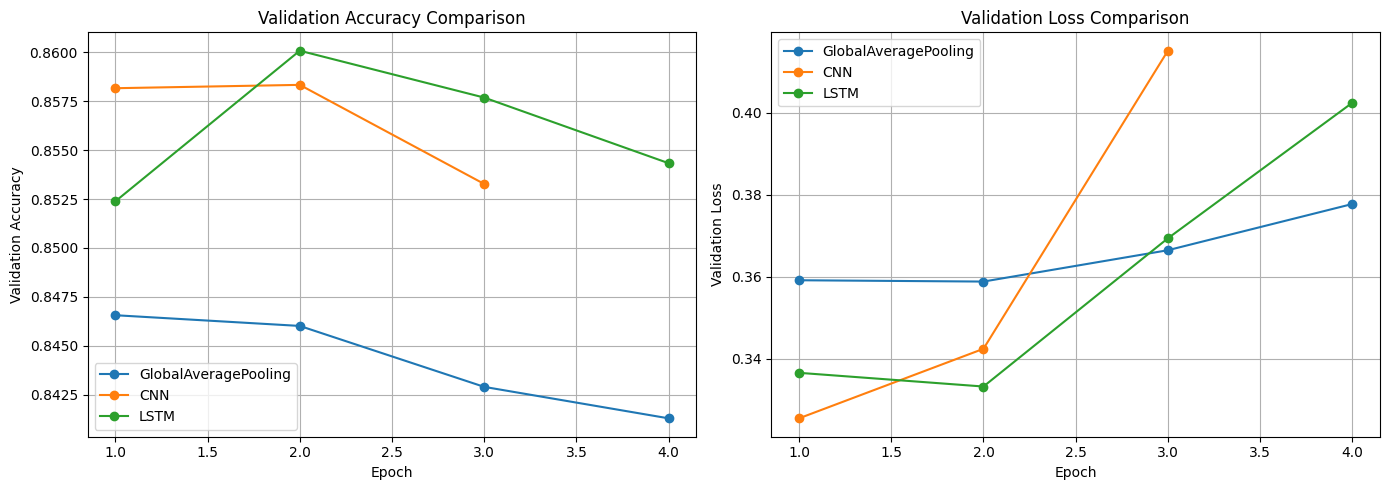

In [34]:

plt.figure(figsize=(14, 5))

# Compare validation accuracy
plt.subplot(1, 2, 1)

for name, history in histories.items():

    values = history.history["val_accuracy"]
    epochs_used = range(1, len(values) + 1)

    plt.plot(
        epochs_used,
        values,
        marker="o",
        label=name
    )

plt.title("Validation Accuracy Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True)

# Compare validation loss
plt.subplot(1, 2, 2)

for name, history in histories.items():

    values = history.history["val_loss"]
    epochs_used = range(1, len(values) + 1)

    plt.plot(
        epochs_used,
        values,
        marker="o",
        label=name
    )

plt.title("Validation Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


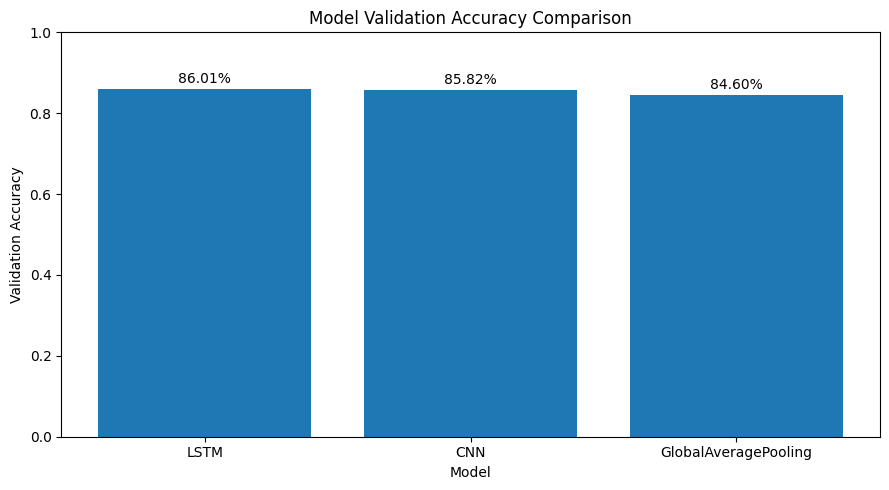

In [35]:

plt.figure(figsize=(9, 5))

bars = plt.bar(
    results_df["Model"],
    results_df["Validation Accuracy"]
)

plt.title("Model Validation Accuracy Comparison")
plt.xlabel("Model")
plt.ylabel("Validation Accuracy")
plt.ylim(0, 1)

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.015,
        f"{height * 100:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()


## 7) 학습된 Embedding 레이어 분석
---

In [36]:

# Get the corrected baseline model
model_avg = models["GlobalAveragePooling"]

# Extract its trained embedding layer
embedding_layer = model_avg.get_layer("avg_embedding")

embedding_weights = embedding_layer.get_weights()[0]

print("Embedding shape:", embedding_weights.shape)

# Check for invalid numerical values
nan_count = np.isnan(embedding_weights).sum()
inf_count = np.isinf(embedding_weights).sum()

print("NaN values:", nan_count)
print("Infinity values:", inf_count)

if nan_count == 0 and inf_count == 0:
    print("Embedding matrix is valid!")
else:
    print("Warning: Invalid embedding values detected.")


Embedding shape: (10000, 100)
NaN values: 0
Infinity values: 0
Embedding matrix is valid!


In [37]:

word = "영화"

if word in word_to_index:

    word_index = word_to_index[word]
    word_vector = embedding_weights[word_index]

    print("Word:", word)
    print("Word index:", word_index)
    print("Vector dimension:", len(word_vector))
    print("\nEmbedding vector:")
    print(word_vector)

else:
    print(f"'{word}' is not in the vocabulary.")


Word: 영화
Word index: 5
Vector dimension: 100

Embedding vector:
[ 0.0121431   0.05542161 -0.02185585  0.0314739  -0.02261913  0.04711568
  0.01564728 -0.04605804  0.09085167  0.00216185 -0.06034056  0.04325653
  0.02017017  0.06963652  0.01871788  0.02938252 -0.0939377  -0.05278181
  0.06409477  0.00745463 -0.05359759 -0.01824556 -0.0269038   0.04123709
 -0.00722839 -0.00362724 -0.01266567 -0.01135019 -0.05420246  0.05606247
  0.0734648   0.04238788  0.01406506 -0.04426763  0.03310939 -0.01567415
 -0.03460523 -0.02857597 -0.08407914 -0.02613893 -0.06082583  0.03608449
 -0.05962332 -0.00556905 -0.05363639  0.00488096 -0.00406692  0.03418826
  0.09093601  0.00070818 -0.04928823 -0.0508536   0.00787881 -0.04122163
 -0.02931355  0.02666434  0.08121524 -0.03895741  0.14413291  0.00162496
  0.04322773 -0.15177059 -0.09853502  0.0508742  -0.0102545   0.00279848
 -0.07058174 -0.04971136  0.02763359 -0.04140319 -0.01947607  0.01914903
 -0.01984893 -0.0076113   0.00273072  0.03164423  0.01199999

In [38]:

import numpy as np

def find_similar_words(word, top_n=10):

    if word not in word_to_index:
        print(f"Word '{word}' not found.")
        return []

    word_index = word_to_index[word]
    target_vector = embedding_weights[word_index]

    # Only use valid embedding vectors
    valid_mask = np.isfinite(
        embedding_weights
    ).all(axis=1)

    # Exclude special tokens and target word
    valid_mask[:4] = False
    valid_mask[word_index] = False

    candidate_indices = np.where(valid_mask)[0]

    if not np.isfinite(target_vector).all():
        print("Target embedding contains NaN or infinity.")
        return []

    if len(candidate_indices) == 0:
        print("No valid candidate embeddings.")
        return []

    candidate_vectors = embedding_weights[candidate_indices]

    # Compute cosine similarity
    target_norm = np.linalg.norm(target_vector)

    candidate_norms = np.linalg.norm(
        candidate_vectors,
        axis=1
    )

    denominator = target_norm * candidate_norms

    similarities = np.divide(
        candidate_vectors @ target_vector,
        denominator,
        out=np.zeros_like(candidate_norms),
        where=denominator > 0
    )

    # Sort by similarity
    sorted_positions = np.argsort(
        similarities
    )[::-1]

    results = []

    for position in sorted_positions:

        index = int(candidate_indices[position])

        if index not in index_to_word:
            continue

        results.append((
            index_to_word[index],
            float(similarities[position])
        ))

        if len(results) >= top_n:
            break

    return results


# Test different words
for word in ["영화", "재미", "좋", "별로"]:

    print(f"\nSimilar words to '{word}':")

    similar_words = find_similar_words(word, top_n=10)

    for similar_word, similarity in similar_words:
        print(f"{similar_word}: {similarity:.4f}")



Similar words to '영화':
게: 0.7082
.: 0.6847
적: 0.6699
완전: 0.6695
고: 0.6655
너무: 0.6654
스피드: 0.6537
진짜: 0.6465
최근: 0.6316
하: 0.6307

Similar words to '재미':
무한: 0.6603
예요: 0.6553
며: 0.6448
완전: 0.6437
머신: 0.6411
연기: 0.6404
고: 0.6302
진짜: 0.6219
마다: 0.6205
,: 0.6188

Similar words to '좋':
Good: 0.8886
소외: 0.8854
넘침: 0.8852
극한: 0.8848
암튼: 0.8847
흘러도: 0.8846
재미나: 0.8815
울려: 0.8800
쪼: 0.8795
흐르: 0.8792

Similar words to '별로':
최악: 0.9716
이딴: 0.9678
재미없: 0.9676
노: 0.9660
개판: 0.9660
짜증: 0.9657
이따위: 0.9654
안습: 0.9652
차라리: 0.9636
쉣: 0.9636


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50689 (\N{HANGUL SYLLABLE YEONG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54868 (\N{HANGUL SYLLABLE HWA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51116 (\N{HANGUL SYLLABLE JAE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48120 (\N{HANGUL SYLLABLE MI}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51339 (\N{HANGUL SYLLABLE JOH}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr

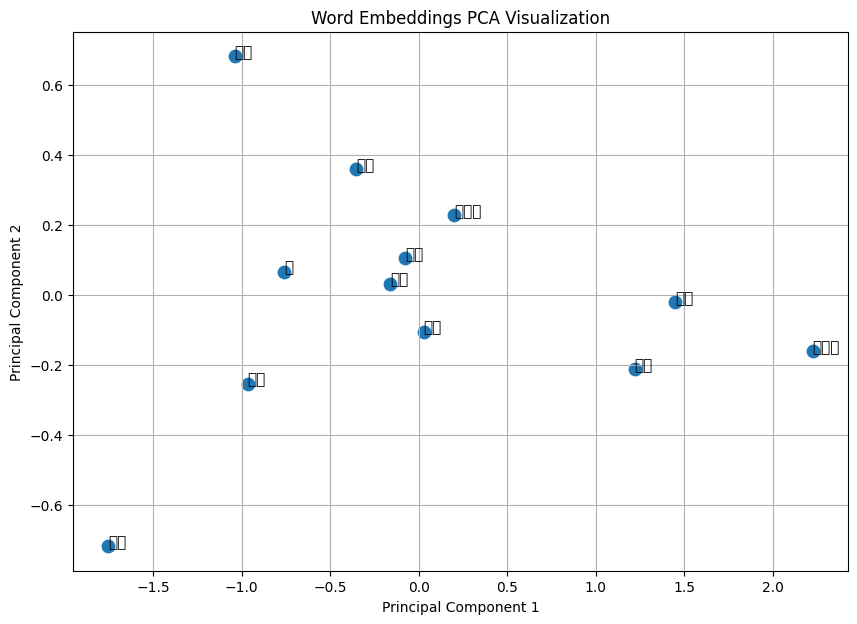

In [39]:

from sklearn.decomposition import PCA

# Choose words for visualization
selected_words = [
    "영화", "재미", "좋", "최고",
    "별로", "재미없", "지루", "감동",
    "배우", "연기", "스토리", "사랑"
]

# Keep only words in vocabulary with valid embeddings
valid_words = [
    word for word in selected_words
    if word in word_to_index
    and np.isfinite(
        embedding_weights[word_to_index[word]]
    ).all()
]

if len(valid_words) < 2:
    print("Not enough valid words for PCA.")
else:
    vectors = np.array([
        embedding_weights[word_to_index[word]]
        for word in valid_words
    ])

    # Reduce to 2D
    pca = PCA(n_components=2)
    reduced_vectors = pca.fit_transform(vectors)

    plt.figure(figsize=(10, 7))

    plt.scatter(
        reduced_vectors[:, 0],
        reduced_vectors[:, 1],
        s=80
    )

    for i, word in enumerate(valid_words):
        plt.annotate(
            word,
            (reduced_vectors[i, 0],
             reduced_vectors[i, 1]),
            fontsize=11
        )

    plt.title("Word Embeddings PCA Visualization")
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.grid(True)
    plt.show()


In [40]:

analysis_words = ["영화", "재미", "좋", "별로"]

embedding_results = []

for word in analysis_words:

    similar = find_similar_words(word, top_n=5)

    for similar_word, score in similar:

        embedding_results.append({
            "Target Word": word,
            "Similar Word": similar_word,
            "Cosine Similarity": score
        })

embedding_df = pd.DataFrame(embedding_results)

display(embedding_df)


,Target Word,Similar Word,Cosine Similarity
0,영화,게,0.708154
1,영화,.,0.684732
2,영화,적,0.669893
3,영화,완전,0.669456
4,영화,고,0.665489
5,재미,무한,0.660307
6,재미,예요,0.655302
7,재미,며,0.644830
8,재미,완전,0.643688
9,재미,머신,0.641075


## 8) 한국어 Word2Vec 임베딩 활용하여 성능 개선
---
- 한국어 Word2Vec은 /data 폴더 안에 있는 word2vec_ko.model을 활용하세요.
- 한국어 Word2Vec을 활용할 때는 `load_word2vec_format()` 형태가 아닌 `load()` 형태로 모델을 불러와주세요. 또한 모델을 활용할 때에는 아래 예시와 같이 `.wv`를 붙여서 활용합니다. 좀더 자세한 활용법에 대해선 다음 링크들을 참조해주세요. [참고 링크1](https://radimrehurek.com/gensim/auto_examples/tutorials/run_word2vec.html#storing-and-loading-models), [참고 링크2](https://radimrehurek.com/gensim/models/keyedvectors.html)



```
# 예시 코드
from gensim.models.keyedvectors import Word2VecKeyedVectors
word_vectors = Word2VecKeyedVectors.load(word2vec_file_path)
vector = word_vectors.wv[‘끝’]
```



In [41]:

from gensim.models import Word2Vec
import numpy as np

# Convert numerical tokens back into words
# Use only the training split to avoid data leakage

sentences = []

for review in X_train_final:
    words = [
        index_to_word[int(idx)]
        for idx in review
        if int(idx) >= 4 and int(idx) in index_to_word
    ]

    if len(words) > 0:
        sentences.append(words)

print("Number of training sentences:", len(sentences))
print("Example sentence:", sentences[0])

# Train Korean Word2Vec
word2vec_model = Word2Vec(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=1,
    workers=1,
    sg=1,
    seed=42,
    epochs=10
)

word2vec = word2vec_model.wv

print("Word2Vec training completed!")
print("Vocabulary size:", len(word2vec))
print("Vector dimension:", word2vec.vector_size)

# Save model
word2vec_model.save(str(DATA_DIR / "word2vec_ko_custom.model"))


Number of training sentences: 116624
Example sentence: ['허니', '잼', '예스', '잼', '꿀', '잼', '잼', '잼']
Word2Vec training completed!
Vocabulary size: 9995
Vector dimension: 100


In [42]:

for word in ["영화", "재미", "배우"]:
    if word in word2vec:
        print(f"\nSimilar words to '{word}':")

        for similar_word, score in word2vec.most_similar(
            word, topn=5
        ):
            print(f"{similar_word}: {score:.4f}")



Similar words to '영화':
작품: 0.6941
공포물: 0.6887
애니메이션: 0.6656
영회: 0.6470
영화광: 0.6327

Similar words to '재미':
제미: 0.6639
스릴: 0.6032
감흥: 0.6022
재미없: 0.5917
,..: 0.5740

Similar words to '배우':
여배우: 0.7007
연기파: 0.6927
존쿠삭: 0.6874
김민준: 0.6593
출연진: 0.6579


In [43]:

vocab_size = max(word_to_index.values()) + 1
word_vector_dim = word2vec.vector_size

rng = np.random.default_rng(42)

embedding_matrix = rng.normal(
    loc=0.0,
    scale=0.05,
    size=(vocab_size, word_vector_dim)
).astype("float32")

# Padding vector
embedding_matrix[0] = 0.0

matched_words = 0

for i in range(4, vocab_size):
    word = index_to_word.get(i)

    if word is not None and word in word2vec:
        embedding_matrix[i] = word2vec[word]
        matched_words += 1

print("Embedding matrix:", embedding_matrix.shape)
print("Matched words:", matched_words)
print(
    "Vocabulary coverage:",
    f"{matched_words / max(vocab_size - 4, 1) * 100:.2f}%"
)

assert np.isfinite(embedding_matrix).all()


Embedding matrix: (10000, 100)
Matched words: 9995
Vocabulary coverage: 99.99%


In [44]:

from tensorflow import keras
from tensorflow.keras import layers

model_word2vec = keras.Sequential([
    layers.Input(shape=(maxlen,)),

    layers.Embedding(
        input_dim=vocab_size,
        output_dim=word_vector_dim,
        weights=[embedding_matrix],
        trainable=True,
        name="word2vec_embedding"
    ),

    layers.Conv1D(
        filters=128,
        kernel_size=5,
        activation="relu"
    ),

    layers.GlobalMaxPooling1D(),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.5),

    layers.Dense(1, activation="sigmoid")
], name="CNN_Word2Vec")

model_word2vec.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model_word2vec.summary()


Model: "CNN_Word2Vec"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ word2vec_embedding (Embedding)  │ (None, 47, 100)        │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 43, 128)        │        64,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_1          │ (None, 128)            │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,072,449 (4.09 MB)

 Trainable params: 1,072,449 (4.09 MB)

 Non-trainable params: 0 (0.00 B)

In [45]:
weights=[embedding_matrix]

In [46]:

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history_word2vec = model_word2vec.fit(
    X_train_final,
    y_train_final,
    epochs=10,
    batch_size=128,
    validation_data=(X_val, y_val),
    callbacks=[
        early_stopping,
        keras.callbacks.TerminateOnNaN()
    ],
    verbose=1
)

print("Training completed!")
print(
    "Best validation accuracy:",
    max(history_word2vec.history["val_accuracy"])
)


Epoch 1/10
914/914 ━━━━━━━━━━━━━━━━━━━━ 70s 76ms/step - accuracy: 0.8367 - loss: 0.3713 - val_accuracy: 0.8624 - val_loss: 0.3176
Epoch 2/10
914/914 ━━━━━━━━━━━━━━━━━━━━ 67s 74ms/step - accuracy: 0.8793 - loss: 0.2900 - val_accuracy: 0.8693 - val_loss: 0.3103
Epoch 3/10
914/914 ━━━━━━━━━━━━━━━━━━━━ 82s 74ms/step - accuracy: 0.9073 - loss: 0.2314 - val_accuracy: 0.8679 - val_loss: 0.3377
Epoch 4/10
914/914 ━━━━━━━━━━━━━━━━━━━━ 67s 74ms/step - accuracy: 0.9357 - loss: 0.1681 - val_accuracy: 0.8597 - val_loss: 0.4343
Training completed!
Best validation accuracy: 0.869343638420105


In [47]:

import pandas as pd

# Original CNN from Section 5
cnn_loss, cnn_acc = models["CNN"].evaluate(
    X_val, y_val, verbose=0
)

# CNN with Word2Vec embeddings
w2v_loss, w2v_acc = model_word2vec.evaluate(
    X_val, y_val, verbose=0
)

comparison = pd.DataFrame([
    {
        "Model": "CNN (Random Embedding)",
        "Validation Accuracy": cnn_acc,
        "Validation Loss": cnn_loss
    },
    {
        "Model": "CNN (Word2Vec)",
        "Validation Accuracy": w2v_acc,
        "Validation Loss": w2v_loss
    }
])

display(comparison)

improvement = (w2v_acc - cnn_acc) * 100

print(
    f"Accuracy difference: {improvement:+.2f} percentage points"
)


,Model,Validation Accuracy,Validation Loss
0,CNN (Random Embedding),0.858159,0.325472
1,CNN (Word2Vec),0.869344,0.310330


Accuracy difference: +1.12 percentage points


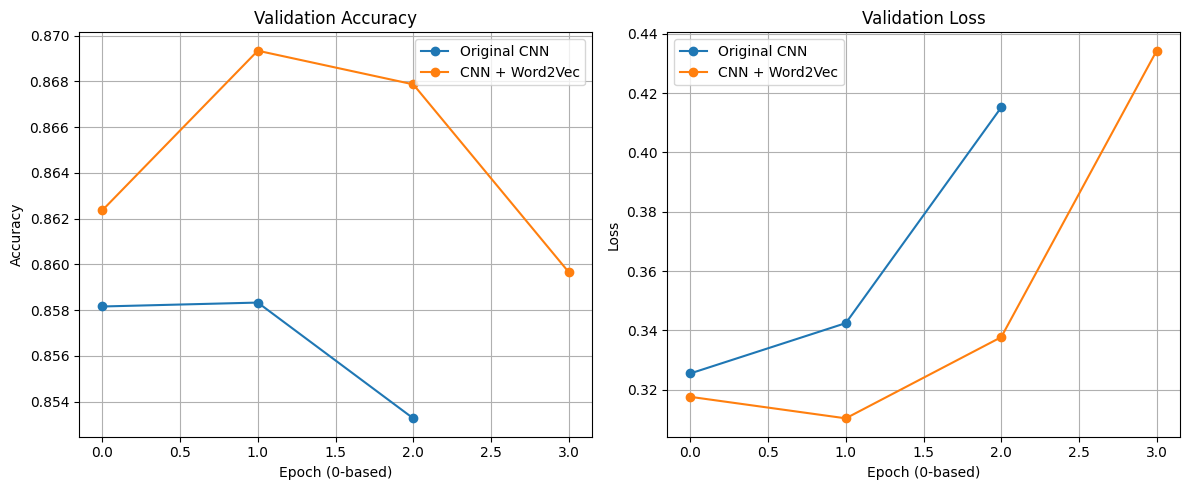

In [48]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(
    histories["CNN"].history["val_accuracy"],
    label="Original CNN",
    marker="o"
)

plt.plot(
    history_word2vec.history["val_accuracy"],
    label="CNN + Word2Vec",
    marker="o"
)

plt.title("Validation Accuracy")
plt.xlabel("Epoch (0-based)")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)

plt.plot(
    histories["CNN"].history["val_loss"],
    label="Original CNN",
    marker="o"
)

plt.plot(
    history_word2vec.history["val_loss"],
    label="CNN + Word2Vec",
    marker="o"
)

plt.title("Validation Loss")
plt.xlabel("Epoch (0-based)")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [49]:

models["CNN_Word2Vec"] = model_word2vec
histories["CNN_Word2Vec"] = history_word2vec

results = []

for name, model in models.items():
    loss, accuracy = model.evaluate(
        X_val, y_val, verbose=0
    )

    results.append({
        "Model": name,
        "Validation Accuracy": accuracy,
        "Validation Loss": loss
    })

final_results_df = pd.DataFrame(results)

final_results_df = final_results_df.sort_values(
    "Validation Accuracy",
    ascending=False
).reset_index(drop=True)

display(final_results_df)

best_model_name = final_results_df.iloc[0]["Model"]
best_model = models[best_model_name]

print("Best model:", best_model_name)


,Model,Validation Accuracy,Validation Loss
0,CNN_Word2Vec,0.869344,0.310330
1,LSTM,0.860075,0.333235
2,CNN,0.858159,0.325472
3,GlobalAveragePooling,0.846017,0.358842


Best model: CNN_Word2Vec


In [50]:

test_loss, test_accuracy = best_model.evaluate(
    X_test_pad,
    y_test,
    verbose=0
)

print("=" * 50)
print("FINAL TEST RESULTS")
print("=" * 50)

print("Selected Model:", best_model_name)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy (%): {test_accuracy * 100:.2f}%")


FINAL TEST RESULTS
Selected Model: CNN_Word2Vec
Test Loss: 0.3141
Test Accuracy: 0.8649
Test Accuracy (%): 86.49%


## 9) gensim으로 두 임베딩 비교

외부 word2vec_ko.model은 제공되지 않아 강의 코드를 수정했다.
NSMC 학습 분할로 Word2Vec을 먼저 학습하고, 이를 CNN의 초기 임베딩으로 사용했다.
여기서 사전학습은 분류기 학습 이전의 Word2Vec 학습을 뜻하며 외부 말뭉치 학습을 뜻하지 않는다.

7절의 감성 분류 중 학습한 Embedding과 8절의 분류 전 학습한 Word2Vec을 비교한다.
아래 셀은 두 임베딩에 동일한 질의어와 gensim most_similar()를 적용한다.
추가 외부 모델 파일은 필요하지 않다.

In [ ]:
from pathlib import Path
from gensim.models import KeyedVectors, Word2Vec

# Exclude reserved IDs and zero vectors before querying cosine neighbours.
def classifier_keyed_vectors(weights, vocabulary):
    """Convert the task-trained Embedding to gensim without reserved tokens."""
    ids = [
        i for i in sorted(vocabulary)
        if i >= 4 and np.isfinite(weights[i]).all()
        and np.linalg.norm(weights[i]) > 0
    ]
    vectors = KeyedVectors(vector_size=weights.shape[1])
    vectors.add_vectors([vocabulary[i] for i in ids], weights[ids])
    return vectors

embedding_sources = {
    'Classifier embedding': classifier_keyed_vectors(
        embedding_weights, index_to_word
    ),
    'NSMC Word2Vec': word2vec_model.wv,
}
query_words = ['영화', '재미', '좋', '별로', '배우']
neighbour_rows = []
for source, vectors in embedding_sources.items():
    for word in query_words:
        if word not in vectors:
            neighbour_rows.append({
                'Embedding': source, 'Query': word,
                'Neighbour': '<OOV>', 'Cosine similarity': np.nan,
            })
            continue
        for neighbour, score in vectors.most_similar(word, topn=5):
            neighbour_rows.append({
                'Embedding': source, 'Query': word,
                'Neighbour': neighbour, 'Cosine similarity': float(score),
            })

neighbour_comparison = pd.DataFrame(neighbour_rows)
display(neighbour_comparison)
neighbour_comparison.to_csv(
    DATA_DIR / 'embedding_neighbours.csv', index=False, encoding='utf-8-sig'
)

### 유사어 비교 해석

기존 저장 출력에서 분류기 Embedding의 ‘별로’는 ‘최악’(0.9716), ‘재미없’(0.9676)과
가까워 부정 감성을 반영한다. ‘영화’의 이웃에는 ‘게’, ‘.’ 등이 있어 의미 관련성은 일관되지 않았다.

NSMC Word2Vec의 ‘영화’는 ‘작품’(0.6941), ‘공포물’(0.6887), ‘애니메이션’(0.6656)과
가까웠고, ‘배우’는 ‘여배우’, ‘연기파’, ‘출연진’ 등과 가까웠다.
분류기 임베딩은 감성 분류 목적함수로, Word2Vec은 주변 단어 예측으로 학습하므로
서로 다른 관계를 반영할 수 있다. 다만 두 목적함수 외에 모델 구조와 학습 조건도 달라
이 차이를 목적함수만의 효과로 단정하지 않는다.

Word2Vec에서 ‘재미’와 ‘재미없’도 가까우므로 문맥 유사도가 감성 일치나 동의어를 의미하지 않는다.
위 해석은 기존 7·8절 출력에 근거한다. 새 공통 질의어 표는 실행하여 출력으로 저장한다.

## 10) 평가기준 점검

제공되지 않은 외부 모델을 필수 조건으로 요구하지 않는다.
분류 중 학습한 임베딩과 직접 사전학습한 Word2Vec의 gensim 유사어 비교를 확인한다.
이 표는 현재 커널의 실행 결과로 판단한다. 최종 제출 전 새 비교 셀과 점검 셀을 실행하고 저장한다.

In [ ]:
required_baselines = {'GlobalAveragePooling', 'CNN', 'LSTM'}
baselines_completed = all(
    name in histories and len(histories[name].history.get('loss', [])) > 0
    for name in required_baselines
)
required_sources = {'Classifier embedding', 'NSMC Word2Vec'}
# Require actual neighbours for each source on at least one shared query.
valid_neighbours = neighbour_comparison[
    neighbour_comparison['Neighbour'] != '<OOV>'
]
shared_queries = set(query_words)
for source in required_sources:
    shared_queries &= set(valid_neighbours.loc[
        valid_neighbours['Embedding'] == source, 'Query'
    ])
compared_embeddings = bool(shared_queries)
rubric_results = pd.DataFrame([
    {
        'Criterion': '1. 한국어 Word2Vec 활용, 테스트 정확도 85% 이상',
        'Passed': bool(best_model_name == 'CNN_Word2Vec' and test_accuracy >= 0.85),
        'Evidence': f'{best_model_name}: test accuracy={test_accuracy:.4%}',
    },
    {
        'Criterion': '2. gensim 자체학습 / 직접 사전학습 임베딩 비교',
        'Passed': compared_embeddings,
        'Evidence': '9절 공통 질의어 비교표 및 해석' if compared_embeddings
                    else '두 임베딩의 공통 질의어 비교 결과 필요',
    },
    {
        'Criterion': '3. 세 가지 이상 모델 학습 성공',
        'Passed': bool(baselines_completed),
        'Evidence': ', '.join(sorted(required_baselines)),
    },
])
display(rubric_results)
print('All criteria passed:', bool(rubric_results['Passed'].all()))

## 11) 결과와 회고

- 평균 풀링, CNN, LSTM의 검증 정확도는 각각 84.60%, 85.82%, 86.01%였다.
- 직접 사전학습한 NSMC Word2Vec으로 초기화한 CNN은 검증 86.93%, 테스트 86.49%였다.
  무작위 초기화 CNN 대비 검증 정확도가 약 1.12%p 높았다.
- 외부 모델 미제공 상황에서 강의 코드를 직접 Word2Vec 학습 방식으로 수정했다.
  분류 중 학습한 임베딩과 분류 전 문맥 기반으로 학습한 임베딩의 유사어 차이를 비교했다.
- EarlyStopping은 검증 손실로 가중치를 복원하고 모델 간 선택은 검증 정확도를 사용했다.
- 한 시드에서의 결과이므로 여러 시드로 성능 개선의 변동성을 확인할 필요가 있다.
- 어휘와 최대 길이는 검증 분리 전에 정했다. 더 엄격한 검증에서는 학습 분할만으로
  어휘와 길이를 정해야 한다. Word2Vec 학습에는 학습 분할만 사용했다.

실행 흐름: 데이터 준비 → 전처리 → 인코딩/패딩 → 학습/검증 분리 → 세 모델 학습 →
임베딩 분석 → Word2Vec 사전학습 → CNN 초기화 및 학습 → 검증 기반 선택 → 테스트 평가 → 유사어 비교.